# Swin-UMamba trên Google Colab (A100): Train / Val / Inference trên BTXRD

Pipeline giống notebook Kaggle `run_10ep.ipynb`: nnU-Net v2, cấu hình **2d**, bài toán phân vùng kèm phân loại (0 = nền, 1 = u lành tính, 2 = u ác tính). Notebook này đã được chỉnh để chạy trên Colab.

**Chuẩn bị (làm 1 lần):**
1. *Runtime → Change runtime type*: chọn **A100 GPU**, bật **High-RAM** nếu có.
2. **Kaggle API token**, dùng để tải 2 dataset Kaggle:
   - `nguyetanhmai/btxrd-split`: dữ liệu BTXRD đã chia train/val/test
   - `nguyetanhmai/setup-envi`: wheel `mamba-ssm` / `causal-conv1d` đã build sẵn

   Vào kaggle.com → *Settings → API → Create New Token*, rồi chọn **một** trong ba cách sau:
   - **(Khuyên dùng)** Mở biểu tượng 🔑 *Secrets* ở thanh bên trái Colab, thêm `KAGGLE_USERNAME` và `KAGGLE_KEY` (KAGGLE_API_TOKEN=.....) , sau đó bật *Notebook access*.
   - Hoặc đặt file `kaggle.json` vào `MyDrive/kaggle.json` trên Google Drive.
   - Hoặc không làm gì trước; khi chạy, notebook sẽ hiện nút để upload `kaggle.json`.
3. **Google Drive:** kết quả (checkpoint, log, dự đoán, metric) và wheel đã build được lưu vào `MyDrive/Swin-UMamba-BTXRD/`. Nếu Colab bị ngắt giữa chừng, chỉ cần *Run all* lại: notebook tự train tiếp từ `checkpoint_latest`.

**Thay đổi số epoch:** chỉ sửa `EPOCHS` ở ô cấu hình. Số epoch đóng băng encoder được tự tính bằng 10% của `EPOCHS` (làm tròn, tối thiểu 1). Mỗi giá trị `EPOCHS` có thư mục kết quả riêng, nên các lần chạy không ghi đè lên nhau.

## 0. Cấu hình

In [ ]:
import os, sys, glob, json, shutil, subprocess

# ================= HUẤN LUYỆN =================
EPOCHS        = 20                                          # <-- chỉ cần chỉnh biến này
FREEZE_RATIO  = 0.10                                        # đóng băng encoder trong 10% số epoch đầu
FREEZE_EPOCHS = max(1, int(EPOCHS * FREEZE_RATIO + 0.5))    # làm tròn thường: 20->2, 25->3, 30->3, 50->5

TRAINER          = "nnUNetTrainerSwinUMambaColab"   # Swin-UMamba + pretrain ImageNet (xem bước 5 để biết các lựa chọn khác)
FOLD             = "0"          # fold 0 = đúng split train/val có sẵn của BTXRD; "all" = train trên train+val
ITERS_PER_EPOCH  = 200          # 200 x batch 16 = 3200 patch/epoch
VAL_ITERS        = 20           # số batch dùng tính pseudo-Dice sau mỗi epoch (bản gốc dùng 50)
SAVE_EVERY       = 1            # chỉ ghi đè checkpoint_latest (mỗi epoch)
BATCH_SIZE       = 8           # A100 40GB với patch ~512x384. Nếu CUDA OOM: 12 hoặc 8. A100 80GB: có thể thử 24
INITIAL_LR       = 3e-4         # cosine giảm về 1e-6 sau EPOCHS epoch
OVERSAMPLE_FG    = 0.66         # quyết định trong mỗi batch có bao nhiêu patch bắt buộc phải chứa khối u. (nnU-Net gốc: 0.33)
CE_CLASS_WEIGHTS = "1,1,2"      # trọng số CE cho (nền, lành, ác). "" = tắt

# ================= DỮ LIỆU =================
KAGGLE_DATA_SLUG = "nguyetanhmai/btxrd-split"
KAGGLE_ENV_SLUG  = "nguyetanhmai/setup-envi"
DATASET_ID   = 705
DATASET_NAME = f"Dataset{DATASET_ID:03d}_BTXRD"
LABEL_MODE   = "benign_malignant"   # "benign_malignant": 0/1/2 | "binary": nền / khối u
MAX_SIZE     = 512                  # resize cạnh dài nhất về <= 512. None = giữ nguyên kích thước

# ================= ĐƯỜNG DẪN =================
REPO_URL  = "https://github.com/67htb5vn/Swin-UMamba.git"
BRANCH    = "main"
REPO      = "/content/Swin-UMamba"
TMP       = "/content/nnunet"            # raw + preprocessed: để trên đĩa local của Colab (nhanh, mất khi ngắt runtime)
KAGGLE_DL = "/content/kaggle_data"       # nơi tải 2 dataset Kaggle về
USE_DRIVE  = True                        # lưu kết quả và wheel lên Google Drive
DRIVE_ROOT = "/content/drive/MyDrive/Swin-UMamba-BTXRD"
RUN_NAME   = f"ep{EPOCHS}"               # thư mục kết quả riêng cho từng giá trị EPOCHS
RESULTS_DIR = f"{DRIVE_ROOT if USE_DRIVE else '/content'}/results/{RUN_NAME}"   # thư mục data/nnUNet_results của repo sẽ trỏ tới đây
WHEEL_STORE = f"{DRIVE_ROOT if USE_DRIVE else '/content'}/wheels"               # nơi lưu wheel mamba build trên Colab

PRETRAIN_URL = "https://github.com/MzeroMiko/VMamba/releases/download/%23v0cls/vssmtiny_dp01_ckpt_epoch_292.pth"

os.environ.update({
    "TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD": "1",              # torch>=2.6 mặc định weights_only=True -> không load được checkpoint nnU-Net
    "nnUNet_n_proc_DA": str(min(12, os.cpu_count() or 4)),  # số tiến trình augmentation (A100 trên Colab có ~12 vCPU)
    "nnUNet_compile": "f",
    "MPLBACKEND": "Agg",
    "SUM_EPOCHS": str(EPOCHS),
    "SUM_ITERS": str(ITERS_PER_EPOCH),
    "SUM_SAVE_EVERY": str(SAVE_EVERY),
    "SUM_VAL_ITERS": str(VAL_ITERS),
    "SUM_FREEZE_EPOCHS": str(FREEZE_EPOCHS),
    "SUM_LR": str(INITIAL_LR),
    "SUM_OVERSAMPLE": str(OVERSAMPLE_FG),
    "SUM_CE_WEIGHTS": CE_CLASS_WEIGHTS if LABEL_MODE == "benign_malignant" else "",
})

print(f"EPOCHS={EPOCHS} | FREEZE_EPOCHS={FREEZE_EPOCHS} ({FREEZE_RATIO:.0%}) | BATCH={BATCH_SIZE} | ITERS={ITERS_PER_EPOCH} | LR={INITIAL_LR}")
print("Kết quả sẽ lưu tại:", RESULTS_DIR)

EPOCHS=20 | FREEZE_EPOCHS=2 (10%) | BATCH=8 | ITERS=200 | LR=0.0003
Kết quả sẽ lưu tại: /content/drive/MyDrive/Swin-UMamba-BTXRD/results/ep20


## 1. Google Drive và kiểm tra GPU

In [2]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_ROOT, exist_ok=True)

!nvidia-smi
import torch
assert torch.cuda.is_available(), "Runtime chưa bật GPU: Runtime -> Change runtime type -> A100 GPU"
gpu = torch.cuda.get_device_name(0)
mem = torch.cuda.get_device_properties(0).total_memory / 2**30
print(f"GPU: {gpu} | {mem:.0f} GB | CPU: {os.cpu_count()} | torch {torch.__version__} | CUDA {torch.version.cuda}")
if "A100" not in gpu:
    print("CẢNH BÁO: GPU hiện tại không phải A100.")
if mem < 30 and BATCH_SIZE > 8:
    print(f"CẢNH BÁO: GPU chỉ có {mem:.0f} GB -> nên giảm BATCH_SIZE xuống 8 (hoặc 4) rồi chạy lại ô cấu hình.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sun Nov 22 09:40:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   37C    P8             16W /   72W |       0MiB /  23034MiB |      0%      Default |
|          

## 2. Tải dataset từ Kaggle
Thứ tự tìm thông tin đăng nhập Kaggle: Colab Secrets (`KAGGLE_USERNAME`/`KAGGLE_KEY`, hoặc `KAGGLE_API_TOKEN`) → `~/.kaggle/kaggle.json` → `MyDrive/Swin-UMamba-BTXRD/kaggle.json` → `MyDrive/kaggle.json` → upload thủ công.

In [3]:
!pip install -q --upgrade kaggle

def setup_kaggle_auth():
    try:
        from google.colab import userdata
        for k in ["KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"]:
            try:
                v = userdata.get(k)
                if v:
                    os.environ[k] = v.strip()   # bỏ khoảng trắng/xuống dòng thừa khi dán
            except Exception:
                pass
    except ImportError:
        pass
    if (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")) or os.environ.get("KAGGLE_API_TOKEN"):
        return "Colab Secrets"
    kj = os.path.expanduser("~/.kaggle/kaggle.json")
    os.makedirs(os.path.dirname(kj), exist_ok=True)
    for p in [kj, f"{DRIVE_ROOT}/kaggle.json", "/content/drive/MyDrive/kaggle.json"]:
        if os.path.isfile(p):
            if p != kj:
                shutil.copy(p, kj)
            os.chmod(kj, 0o600)
            return p
    from google.colab import files
    print("Không tìm thấy thông tin đăng nhập Kaggle -> hãy upload file kaggle.json")
    up = files.upload()
    name = next(n for n in up if n.endswith(".json"))
    open(kj, "wb").write(up[name])
    os.chmod(kj, 0o600)
    return "upload"

def kaggle_download(slug, dest):
    if os.path.isdir(dest) and any(os.scandir(dest)):
        print("Đã có sẵn:", dest)
        return
    os.makedirs(dest, exist_ok=True)
    print("Đang tải", slug, "->", dest)
    # Cách 1: kaggle CLI (in rõ thông báo lỗi nếu thất bại)
    r = subprocess.run(["kaggle", "datasets", "download", "-d", slug, "-p", dest, "--unzip"],
                       capture_output=True, text=True)
    print(r.stdout[-2000:], r.stderr[-2000:])
    if r.returncode == 0 and any(os.scandir(dest)):
        return
    # Cách 2: kagglehub (dùng cùng thông tin đăng nhập)
    print("kaggle CLI lỗi -> thử kagglehub...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kagglehub"], check=False)
    import kagglehub
    path = kagglehub.dataset_download(slug)
    print("kagglehub tải về:", path)
    shutil.rmtree(dest)
    os.symlink(path, dest)

def check_kaggle_auth():
    r = subprocess.run(["kaggle", "datasets", "list", "--mine"], capture_output=True, text=True)
    print("Kiểm tra đăng nhập Kaggle (datasets của tài khoản):")
    print(r.stdout[-1500:] or r.stderr[-1500:])
    for k in ["KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"]:
        v = os.environ.get(k, "")
        print(f"  {k}: {'(trống)' if not v else ('độ dài ' + str(len(v)) + (', CÓ khoảng trắng/xuống dòng thừa!' if v != v.strip() else ''))}")

print("Kaggle auth:", setup_kaggle_auth())
check_kaggle_auth()
kaggle_download(KAGGLE_DATA_SLUG, f"{KAGGLE_DL}/btxrd")
kaggle_download(KAGGLE_ENV_SLUG, f"{KAGGLE_DL}/env")

def find_btxrd(root):
    """Tìm thư mục gốc chứa train/ val/ test/ (mỗi tập gồm images/ + Annotations/)."""
    for p in sorted(glob.glob(f"{root}/**/train/Annotations", recursive=True)):
        d = os.path.dirname(os.path.dirname(p))
        if all(os.path.isdir(os.path.join(d, s, "images")) for s in ["train", "val", "test"]):
            return d
    return None

BTXRD_DIR = find_btxrd(f"{KAGGLE_DL}/btxrd")
assert BTXRD_DIR, f"Không tìm thấy cấu trúc train/val/test trong {KAGGLE_DL}/btxrd"
print("BTXRD_DIR =", BTXRD_DIR, "->", sorted(os.listdir(BTXRD_DIR)))
for s in ["train", "val", "test"]:
    print(f"  {s}: {len(os.listdir(f'{BTXRD_DIR}/{s}/images'))} ảnh, {len(glob.glob(f'{BTXRD_DIR}/{s}/Annotations/*.json'))} json")
print("Wheel từ Kaggle:", glob.glob(f"{KAGGLE_DL}/env/**/*.whl", recursive=True))

Kaggle auth: Colab Secrets
Kiểm tra đăng nhập Kaggle (datasets của tài khoản):
uyen24a/data-sach          data_sach             2750883  2026-04-22 08:55:16.187000              0          0  0.1875           
hoangnguyen24a/vungmien           vungmien              1249434  2026-04-22 08:41:52.403000              0          0  0.1764706        
hoangnguyen24a/data-test          data test              250857  2026-04-18 13:25:25.597000              0          0  0.1875           
hoangnguyen24a/doc-bien-so-xe     doc_bien_so_xe       46173453  2026-11-16 12:49:37.777000              0          0  0.11764706       
hoangnguyen24a/resnet34-pretrain  resnet34_pretrain    81001896  2026-10-20 08:04:33.103000              0          0  0.25             
hoangnguyen24a/resnet18-pretrain  resnet18-pretrain    43451679  2026-09-16 14:01:28.750000              0          0  0.25             
hoangnguyen24a/cifar-10           cifar-10            170063312  2026-05-05 02:17:50.567000              0

## 3. Clone repo từ GitHub

In [4]:
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, REPO], check=True)
else:
    subprocess.run(["git", "-C", REPO, "pull"], check=False)
!git -C {REPO} log --oneline -1

a860754 (grafted, HEAD -> main, origin/main, origin/HEAD) run a100


## 4. Cài môi trường
- Cài nnU-Net bản sửa đổi và các thư viện thuần Python (mất khoảng 1–2 phút).
- `mamba-ssm` và `causal-conv1d`: notebook thử lần lượt các bộ wheel theo thứ tự (1) wheel Colab đã lưu trên Drive, (2) wheel trong dataset Kaggle `setup-envi`. Mỗi bộ được kiểm tra bằng cách chạy thử kernel CUDA.
- Wheel `setup-envi` được build trên Kaggle. Nếu phiên bản torch/CUDA/Python của Colab khác Kaggle thì wheel đó không chạy được, và notebook sẽ **tự build lại** (lần đầu mất khoảng 10–30 phút). Wheel mới được lưu lên Drive (`MyDrive/Swin-UMamba-BTXRD/wheels/<env_tag>/`), nên các lần sau chỉ cần cài lại.

In [ ]:
# Cài torch 2.11 + nnU-Net + numpy 2 rồi tự restart 1 lần (trước khi kernel nạp numpy)
MARK = "/content/.env_ready"
if not os.path.exists(MARK):
    !pip install -q torch==2.11.0 torchvision --index-url https://download.pytorch.org/whl/cu130
    !cd {REPO}/swin_umamba && pip install -q -e . && pip install -q "monai==1.4.0" timm torchinfo einops numba packaging ninja
    !pip install -q "numpy>=2.1,<2.6"
    open(MARK, "w").close()
    os.kill(os.getpid(), 9)   # restart -> bấm Run all lần nữa
import torch, numpy; print("torch", torch.__version__, "| numpy", numpy.__version__)

In [6]:
import torch
ENV_TAG = f"torch{torch.__version__.split('+')[0]}-cu{torch.version.cuda}-py{sys.version_info.major}{sys.version_info.minor}"
print("ENV_TAG hiện tại:", ENV_TAG)

def wheel_candidates():
    """Các thư mục chứa đủ 2 wheel; ưu tiên thư mục có env_tag khớp, rồi đến wheel trên Drive."""
    dirs = sorted({os.path.dirname(p) for root in [WHEEL_STORE, f"{KAGGLE_DL}/env"]
                   for p in glob.glob(f"{root}/**/mamba_ssm-*.whl", recursive=True)})
    cands = []
    for d in dirs:
        if not glob.glob(f"{d}/causal_conv1d-*.whl"):
            continue
        tag_file = f"{d}/env_tag.txt"
        tag = open(tag_file).read().strip() if os.path.isfile(tag_file) else "?"
        print(f"  tìm thấy wheel: {d}  (env_tag={tag})")
        cands.append((tag != ENV_TAG, not d.startswith(WHEEL_STORE), d))
    return [d for *_, d in sorted(cands)]

def mamba_ok():
    test = ("import torch; from mamba_ssm.ops.selective_scan_interface import selective_scan_fn; "
            "u=torch.randn(1,4,16,device='cuda'); A=-torch.rand(4,8,device='cuda'); B=torch.randn(1,8,16,device='cuda'); "
            "selective_scan_fn(u,u,A,B,B); import causal_conv1d")
    return subprocess.run([sys.executable, "-c", test], capture_output=True).returncode == 0

%cd {REPO}/swin_umamba
!pip install -q --no-deps -e .
# setup.py ghim monai==1.3.0 (không tương thích numpy 2) -> dùng 1.4.0, API các block giữ nguyên
!pip install -q "monai==1.4.0" timm torchinfo einops numba packaging ninja

ok = False
for d in wheel_candidates():
    print("Thử cài mamba từ:", d)
    !pip install -q --no-deps --force-reinstall {d}/causal_conv1d-*.whl {d}/mamba_ssm-*.whl
    ok = mamba_ok()
    print("  -> dùng được" if ok else "  -> KHÔNG tương thích với torch hiện tại")
    if ok:
        break

if not ok:
    print("Không có wheel phù hợp -> build wheel cho môi trường Colab (lần đầu sẽ lâu)...")
    os.environ["MAX_JOBS"] = str(os.cpu_count() or 4)
    WHEEL_OUT = f"{WHEEL_STORE}/{ENV_TAG}"
    !rm -rf "{WHEEL_OUT}" && mkdir -p "{WHEEL_OUT}"
    !pip wheel -q --no-build-isolation --no-deps causal-conv1d mamba-ssm -w "{WHEEL_OUT}"
    !pip install -q --no-deps --force-reinstall "{WHEEL_OUT}"/causal_conv1d-*.whl "{WHEEL_OUT}"/mamba_ssm-*.whl
    open(f"{WHEEL_OUT}/env_tag.txt", "w").write(ENV_TAG)
    !ls -la "{WHEEL_OUT}"
    assert mamba_ok(), "Build xong nhưng kernel mamba vẫn lỗi -> xem log pip phía trên"
%cd {REPO}

ENV_TAG hiện tại: torch2.11.0-cu13.0-py313
/content/Swin-UMamba/swin_umamba
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for nnunetv2 (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
nnunetv2 2.1.1 requires monai==1.3.0, but you have monai 1.4.0 which is incompatible.
imagecodecs 2026.11.11 requires numpy>=2.1, but you have numpy 1.26.4 which is inco

In [7]:
# Kiểm tra kernel CUDA selective_scan của mamba và đường dẫn nnU-Net
check = ("import torch, mamba_ssm; "
         "from mamba_ssm.ops.selective_scan_interface import selective_scan_fn; "
         "u=torch.randn(1,4,16,device='cuda'); d=torch.randn(1,4,16,device='cuda'); A=-torch.rand(4,8,device='cuda'); "
         "B=torch.randn(1,8,16,device='cuda'); C=torch.randn(1,8,16,device='cuda'); "
         "print('torch', torch.__version__, '| mamba_ssm', mamba_ssm.__version__, '| out', selective_scan_fn(u,d,A,B,C).shape)")
subprocess.run([sys.executable, "-c", check], check=True)
!python -c "import nnunetv2, monai; from nnunetv2.paths import nnUNet_raw, nnUNet_results; print('nnUNet_raw =', nnUNet_raw); print('nnUNet_results =', nnUNet_results)"

I0000 00:00:1795340638.691794    6247 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795340638.766132    6247 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
nnUNet_raw = /content/Swin-UMamba/data/nnUNet_raw
nnUNet_results = /content/Swin-UMamba/data/nnUNet_results


## 5. Tải pretrained VMamba-Tiny và tạo thư mục dữ liệu
- `data/nnUNet_raw/<dataset>` và `data/nnUNet_preprocessed` là symlink tới `/content/nnunet` (đĩa local, tốc độ nhanh).
- `data/nnUNet_results` là symlink tới `RESULTS_DIR` trên Google Drive. Checkpoint được ghi thẳng lên Drive.

In [8]:
os.chdir(REPO)
ckpt = f"{REPO}/data/pretrained/vmamba/vmamba_tiny_e292.pth"
os.makedirs(os.path.dirname(ckpt), exist_ok=True)
import urllib.request
if os.path.isfile(ckpt) and os.path.getsize(ckpt) < 50 * 2**20:   # file hỏng do lần tải trước bị lỗi
    os.remove(ckpt)
if not os.path.isfile(ckpt):
    urllib.request.urlretrieve(PRETRAIN_URL, ckpt + ".part")
    os.rename(ckpt + ".part", ckpt)
assert os.path.getsize(ckpt) > 50 * 2**20, "File pretrained không hợp lệ"
print("pretrained:", ckpt, os.path.getsize(ckpt) // 2**20, "MB")

RAW_DS = f"{TMP}/nnUNet_raw/{DATASET_NAME}"
os.makedirs(RAW_DS, exist_ok=True)
os.makedirs(f"{TMP}/nnUNet_preprocessed", exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(f"{REPO}/data/nnUNet_raw", exist_ok=True)

def force_symlink(link, target):
    if os.path.islink(link):
        if os.readlink(link) == target:
            return
        os.unlink(link)
    elif os.path.isdir(link):          # thư mục thật (vd có sẵn trong repo) -> chép nội dung sang target rồi thay bằng symlink
        subprocess.run(["cp", "-rn", f"{link}/.", target], check=False)
        shutil.rmtree(link)
    os.symlink(target, link)

force_symlink(f"{REPO}/data/nnUNet_raw/{DATASET_NAME}", RAW_DS)
force_symlink(f"{REPO}/data/nnUNet_preprocessed", f"{TMP}/nnUNet_preprocessed")
force_symlink(f"{REPO}/data/nnUNet_results", RESULTS_DIR)
!ls -la {REPO}/data

pretrained: /content/Swin-UMamba/data/pretrained/vmamba/vmamba_tiny_e292.pth 87 MB
total 4764
drwxr-xr-x 5 root root    4096 Nov 22 09:44 .
drwxr-xr-x 8 root root    4096 Nov 22 09:38 ..
drwxr-xr-x 5 root root    4096 Nov 22 09:38 BTXRD
-rw-r--r-- 1 root root 4857659 Nov 22 09:38 BTXRD.zip
lrwxrwxrwx 1 root root      35 Nov 22 09:44 nnUNet_preprocessed -> /content/nnunet/nnUNet_preprocessed
drwxr-xr-x 5 root root    4096 Nov 22 09:44 nnUNet_raw
lrwxrwxrwx 1 root root      53 Nov 22 09:44 nnUNet_results -> /content/drive/MyDrive/Swin-UMamba-BTXRD/results/ep20
drwxr-xr-x 3 root root    4096 Nov 22 09:38 pretrained


## 6. Trainer tuỳ chỉnh
Trainer kế thừa trainer gốc của Swin-UMamba (AdamW, cosine schedule, deep supervision, pretrain VMamba-Tiny) và đọc siêu tham số từ biến môi trường do ô cấu hình đặt:

| Tham số | Gốc (~350 epoch) | Ở đây |
|---|---|---|
| `num_epochs` | 1000 (dừng sớm 350) | `EPOCHS` |
| `freeze_encoder_epochs` | 10 | `FREEZE_EPOCHS` = 10% × `EPOCHS` |
| `initial_lr` | 1e-4 | `INITIAL_LR` |
| `num_val_iterations_per_epoch` | 50 | `VAL_ITERS` |
| `oversample_foreground_percent` | 0.33 | `OVERSAMPLE_FG` |
| Trọng số CE | không | `CE_CLASS_WEIGHTS` |

Các trainer có sẵn (đặt vào biến `TRAINER`): `nnUNetTrainerSwinUMambaColab`, `nnUNetTrainerSwinUMambaDColab` (Swin-UMamba†), `nnUNetTrainerSwinUMambaScratchColab`, `nnUNetTrainerSwinUMambaDScratchColab` (hai trainer cuối không dùng pretrain).

Trainer không lưu `checkpoint_{epoch}.pth` (khoảng 0.5 GB mỗi file, sẽ làm đầy Drive). Vẫn giữ `checkpoint_latest`, `checkpoint_best` và `checkpoint_final`.

In [ ]:
trainer_src = """
import os
import torch
from nnunetv2.training.nnUNetTrainer.nnUNetTrainer import nnUNetTrainer
from nnunetv2.training.nnUNetTrainer.nnUNetTrainerSwinUMamba import nnUNetTrainerSwinUMamba
from nnunetv2.training.nnUNetTrainer.nnUNetTrainerSwinUMambaD import nnUNetTrainerSwinUMambaD
from nnunetv2.training.nnUNetTrainer.nnUNetTrainerSwinUMambaScratch import nnUNetTrainerSwinUMambaScratch
from nnunetv2.training.nnUNetTrainer.nnUNetTrainerSwinUMambaDScratch import nnUNetTrainerSwinUMambaDScratch
from nnunetv2.training.loss.compound_losses import DC_and_CE_loss


def _custom_setup(self):
    env = os.environ.get
    self.num_epochs = int(env("SUM_EPOCHS", 20))
    self.num_iterations_per_epoch = int(env("SUM_ITERS", 200))
    self.num_val_iterations_per_epoch = int(env("SUM_VAL_ITERS", 20))
    self.save_every = int(env("SUM_SAVE_EVERY", 1))
    self.freeze_encoder_epochs = int(env("SUM_FREEZE_EPOCHS", max(1, round(self.num_epochs * 0.1))))
    self.initial_lr = float(env("SUM_LR", 3e-4))
    self.oversample_foreground_percent = float(env("SUM_OVERSAMPLE", 0.66))
    w = env("SUM_CE_WEIGHTS", "").strip()
    self.ce_class_weights = [float(x) for x in w.split(",")] if w else None


def _build_loss_weighted(self):
    # Dựng loss mặc định của nnU-Net (Dice + CE, có thể bọc deep supervision),
    loss = nnUNetTrainer._build_loss(self)
    w = self.ce_class_weights

    # Chỉ áp dụng khi KHÔNG huấn luyện theo vùng (region-based).
    # Region-based dùng BCE thay cho CE, nên trọng số CE không có ý nghĩa.
    if w and not self.label_manager.has_regions:
        # Số trọng số phải bằng số lớp đầu ra (tính cả lớp nền)
        assert len(w) == self.label_manager.num_segmentation_heads, f"SUM_CE_WEIGHTS cần {self.label_manager.num_segmentation_heads} giá trị"

        # Khi bật deep supervision, loss bị bọc trong DeepSupervisionWrapper,
        # loss thật nằm ở thuộc tính .loss -> bóc lớp vỏ ra
        dc_ce = loss.loss if hasattr(loss, "loss") else loss
        assert isinstance(dc_ce, DC_and_CE_loss)

        # dc_ce.ce là một nn.CrossEntropyLoss -> gán tensor trọng số trực tiếp,
        # đặt đúng device (GPU) để khớp với output của mạng
        dc_ce.ce.weight = torch.tensor(w, dtype=torch.float32, device=self.device)
        self.print_to_log_file(f"CE class weights: {w}")
    return loss

"""
# ============================================================================
# Sinh lớp con, mỗi lớp kế thừa một trainer gốc và thêm hậu tố "Colab".
# ============================================================================
for base in ["nnUNetTrainerSwinUMamba"]:
    trainer_src += f"""
class {base}Colab({base}):
    def __init__(self, plans: dict, configuration: str, fold: int, dataset_json: dict,
                 unpack_dataset: bool = True, device: torch.device = torch.device("cuda")):
        # Khởi tạo như lớp cha (giữ nguyên chữ ký hàm mà nnU-Net yêu cầu)
        super().__init__(plans, configuration, fold, dataset_json, unpack_dataset, device)
        # Rồi ghi đè siêu tham số. Đặt sau super() vẫn kịp vì mạng, optimizer,
        # scheduler, loss và dataloader chỉ được dựng sau đó, khi bắt đầu train.
        _custom_setup(self)
        self.print_to_log_file(f"[Colab] epochs={{self.num_epochs}} freeze={{self.freeze_encoder_epochs}} "
                               f"iters={{self.num_iterations_per_epoch}} lr={{self.initial_lr}}")

    def _build_loss(self):
        # Thay hàm dựng loss bằng phiên bản có trọng số lớp
        return _build_loss_weighted(self)

    def on_epoch_end(self):
        # Gọi THẲNG hàm của nnUNetTrainer gốc, bỏ qua bản ghi đè của trainer Swin-UMamba,
        # vì bản đó lưu thêm checkpoint_{{epoch}}.pth sau MỖI epoch -> đầy ổ đĩa Colab.
        # Hàm gốc vẫn ghi log, lưu checkpoint_latest (theo save_every) và checkpoint_best.
        nnUNetTrainer.on_epoch_end(self)

"""
path = f"{REPO}/swin_umamba/nnunetv2/training/nnUNetTrainer/nnUNetTrainerSwinUMambaColab.py"
open(path, "w").write(trainer_src)
!python -c "from nnunetv2.training.nnUNetTrainer.nnUNetTrainerSwinUMambaColab import *; print('OK')"

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
I0000 00:00:1795340657.430732    6388 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795340657.508425    6388 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/content/Swin-UMamba/swin_umamba/nnunetv2/training/nnUNetTrainer/nnUNetTrainerSwinUMambaD.py:18: SyntaxWarning: invalid escape se

## 7. Chuyển BTXRD sang định dạng nnU-Net
- Chỉ dùng nhãn **polygon** (vùng khối u); bỏ qua `rectangle` (bbox).
- Lớp lành/ác lấy từ cột `type` trong `split.csv`. Nếu ảnh không có trong csv thì suy ra từ tên nhãn (`osteosarcoma`, `other mt`, `*sarcoma` → ác tính).
- Mask PNG: 0 = nền, 1 = lành tính, 2 = ác tính.
- `train` + `val` → `imagesTr/labelsTr`; `test` → `imagesTs/labelsTs`. Danh sách train/val được ghi ra `splits_final.json` để fold 0 validate đúng trên tập `val`.

In [ ]:
# ============================================================================
# convert_src là MÃ NGUỒN của một script độc lập, được ghi ra file
# convert_btxrd.py rồi chạy bằng lệnh shell bên dưới.
# Tiền tố r"""...""" (raw string) giữ nguyên các dấu \ nếu có trong code.
# ============================================================================
convert_src = r"""
import os, sys, json, glob, csv
import numpy as np, cv2
from PIL import Image, ImageOps

# Tham số dòng lệnh:
#   src      : thư mục BTXRD gốc (chứa train/ val/ test/)
#   out      : thư mục raw của nnU-Net (nnUNet_raw/DatasetXXX_Tên)
#   meta     : nơi ghi splits_final.json và cases.csv
#   mode     : "binary" (nền / u) hoặc "benign_malignant" (nền / lành / ác)
#   max_size : cạnh dài tối đa sau khi thu nhỏ ảnh ("None" = giữ nguyên)
#   name     : tên dataset ghi vào dataset.json
src, out, meta, mode, max_size, name = sys.argv[1:7]
max_size = int(max_size) if max_size != "None" else None

# ---------------------------------------------------------------------------
# Đọc split.csv (nếu có) để biết mỗi ảnh là u LÀNH hay ÁC tính.
# ---------------------------------------------------------------------------
types = {}
for p in [os.path.join(src, "split.csv"), os.path.join(os.path.dirname(src), "split.csv")]:
    if os.path.isfile(p):
        for r in csv.DictReader(open(p, encoding="utf-8-sig")):
            if r.get("image_id") and r.get("type"):
                types[os.path.splitext(r["image_id"].strip())[0]] = r["type"].strip().lower()
        print("split.csv:", p, "|", len(types), "ảnh có type")
        break


labels = {"background": 0, "benign": 1, "malignant": 2}
# nhận vào stem (tên ảnh, không có đuôi) và l (tên nhãn của polygon trong file LabelMe), 
# rồi trả về 2 nếu là u ác, còn lại trả về 1.
cls = lambda stem, l: 2 if is_malignant(stem, l) else 1

# Cấu trúc thư mục nnU-Net: imagesTr/labelsTr (train + val), imagesTs/labelsTs (test)
for d in ["imagesTr", "labelsTr", "imagesTs", "labelsTs"]:
    os.makedirs(os.path.join(out, d), exist_ok=True)
os.makedirs(meta, exist_ok=True)

ids = {"train": [], "val": [], "test": []}   # danh sách ca theo từng split
info = []                                    # thông tin từng ca, ghi ra cases.csv
for split in ["train", "val", "test"]:
    sdir = os.path.join(src, split)
    # {tên ảnh không đuôi -> đường dẫn ảnh}, để ghép với file JSON cùng tên
    imgs = {os.path.splitext(f)[0]: os.path.join(sdir, "images", f) for f in os.listdir(os.path.join(sdir, "images"))}
    # train và val đều vào ...Tr (nnU-Net tự chia lại theo splits_final.json); test vào ...Ts
    sub = "Ts" if split == "test" else "Tr"
    skipped = 0
    for jf in sorted(glob.glob(os.path.join(sdir, "Annotations", "*.json"))):
        stem = os.path.splitext(os.path.basename(jf))[0]
        ann = json.load(open(jf, encoding="utf-8"))

        # Chỉ lấy polygon hợp lệ (ít nhất 3 đỉnh); bỏ rectangle, point, line...
        polys = [s for s in ann["shapes"] if s.get("shape_type") == "polygon" and len(s["points"]) >= 3]
        if stem not in imgs or not polys:      # không có ảnh hoặc không có polygon -> bỏ qua
            skipped += 1
            continue

        # Hệ số tỉ lệ nếu kích thước ảnh thật khác kích thước lúc vẽ nhãn
        sx = w / float(ann.get("imageWidth") or w)
        sy = h / float(ann.get("imageHeight") or h)

        # Vẽ mặt nạ: tô polygon lớp 1 (lành) trước, lớp 2 (ác) sau.
        # Chỗ hai polygon chồng nhau, lớp ác tính vẽ sau sẽ đè lên -> ưu tiên ác tính.
        mask = np.zeros((h, w), np.uint8)
        for c in (1, 2):   # vẽ ác tính sau để ưu tiên khi chồng lấn
            for s in polys:
                if cls(stem, s["label"]) == c:
                    # nhân tỉ lệ, làm tròn thành toạ độ pixel nguyên cho cv2.fillPoly
                    pts = np.array([[x * sx, y * sy] for x, y in s["points"]], np.float64).round().astype(np.int32)
                    cv2.fillPoly(mask, [pts], c)

        img = np.array(img)

        # Thu nhỏ nếu cạnh dài vượt max_size (giữ nguyên tỉ lệ khung hình).
        # Ảnh dùng INTER_AREA (thu nhỏ mịn, ít răng cưa).
        # Mặt nạ BẮT BUỘC dùng INTER_NEAREST, để giá trị vẫn là 0/1/2 (không sinh ra 0.5, 1.5...).
        if max_size and max(h, w) > max_size:
            r = max_size / max(h, w)
            nw, nh = int(round(w * r)), int(round(h * r))
            img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
            mask = cv2.resize(mask, (nw, nh), interpolation=cv2.INTER_NEAREST)

        # Quy ước tên file của nnU-Net:
        #   ảnh   : <ca>_0000.png  (_0000 = kênh số 0; ảnh nhiều kênh sẽ có _0001, _0002...)
        #   nhãn  : <ca>.png       (cùng tên ca, không có hậu tố kênh)
        cv2.imwrite(os.path.join(out, f"images{sub}", f"{stem}_0000.png"), img)
        cv2.imwrite(os.path.join(out, f"labels{sub}", f"{stem}.png"), mask)
        ids[split].append(stem)

        # Ghi lại: tên ca, split, lành/ác (theo mặt nạ), các tên nhãn gốc nối bằng "|"
        info.append((stem, split, "malignant" if mask.max() == 2 else "benign", "|".join(sorted({s["label"] for s in polys}))))
    print(f"{split}: {len(ids[split])} ảnh (bỏ qua {skipped} ảnh không có polygon/ảnh)")

# dataset.json bắt buộc của nnU-Net v2:
#   channel_names : tên từng kênh đầu vào (1 kênh X-quang)
#   labels        : tên lớp -> giá trị pixel
#   numTraining   : số ca trong imagesTr (= train + val)
#   file_ending   : đuôi file ảnh/nhãn
json.dump({"channel_names": {"0": "X-ray"}, "labels": labels, "numTraining": len(ids["train"]) + len(ids["val"]),
           "file_ending": ".png", "name": name,
           "description": f"BTXRD bone tumor X-ray, polygons -> segmentation masks ({mode})"},
          open(os.path.join(out, "dataset.json"), "w"), indent=2)

# splits_final.json: ép nnU-Net dùng ĐÚNG cách chia train/val có sẵn của BTXRD
# thay vì tự chia 5-fold. Danh sách 1 phần tử = chỉ có fold 0.
json.dump([{"train": sorted(ids["train"]), "val": sorted(ids["val"])}], open(os.path.join(meta, "splits_final.json"), "w"), indent=2)

# cases.csv: bảng tra cứu từng ca, tiện cho thống kê / phân tích lỗi sau này
with open(os.path.join(meta, "cases.csv"), "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["case", "split", "type", "labels"]); wr.writerows(info)
print("labels:", labels)
"""

# Ghi script ra file tạm
open(f"{TMP}/convert_btxrd.py", "w").write(convert_src)
META = f"{TMP}/btxrd_meta"

# ---------------------------------------------------------------------------
# Chỉ chuyển đổi khi CHƯA có dữ liệu hợp lệ, để tránh làm lại mỗi lần chạy notebook.
# Coi là hợp lệ khi: có dataset.json, số lớp khớp LABEL_MODE hiện tại,
# và đã có splits_final.json.
# ---------------------------------------------------------------------------
ds_json = f"{RAW_DS}/dataset.json"
n_labels = 3 if LABEL_MODE == "benign_malignant" else 2
if not (os.path.isfile(ds_json) and len(json.load(open(ds_json))["labels"]) == n_labels and os.path.isfile(f"{META}/splits_final.json")):
    !rm -rf {RAW_DS}/* {META}          # xoá dữ liệu cũ (ví dụ của chế độ nhãn khác)
    !python {TMP}/convert_btxrd.py "{BTXRD_DIR}" "{RAW_DS}" "{META}" {LABEL_MODE} {MAX_SIZE} {DATASET_NAME}
else:
    print("Dữ liệu nnU-Net đã có sẵn, bỏ qua bước chuyển đổi")

# In dataset.json và đếm số file trong từng thư mục để kiểm tra nhanh
!cat {RAW_DS}/dataset.json
for d in ["imagesTr", "labelsTr", "imagesTs", "labelsTs"]:
    print(d, len(glob.glob(f"{RAW_DS}/{d}/*")))

split.csv: /content/kaggle_data/btxrd/BTXRD_split/split.csv | 1867 ảnh có type
train: 1494 ảnh (bỏ qua 0 ảnh không có polygon/ảnh)
val: 280 ảnh (bỏ qua 0 ảnh không có polygon/ảnh)
test: 93 ảnh (bỏ qua 0 ảnh không có polygon/ảnh)
labels: {'background': 0, 'benign': 1, 'malignant': 2}
{
  "channel_names": {
    "0": "X-ray"
  },
  "labels": {
    "background": 0,
    "benign": 1,
    "malignant": 2
  },
  "numTraining": 1774,
  "file_ending": ".png",
  "name": "Dataset705_BTXRD",
  "description": "BTXRD bone tumor X-ray, polygons -> segmentation masks (benign_malignant)"
}imagesTr 1774
labelsTr 1774
imagesTs 93
labelsTs 93


## 8. Plan & preprocess

In [ ]:
os.chdir(REPO)
NP = os.environ["nnUNet_n_proc_DA"]

# Lệnh tiền xử lý của nnU-Net, gồm 3 việc:
#   1. Fingerprint : thống kê dataset (kích thước ảnh, spacing, phân bố cường độ...)
#   2. Plan        : từ thống kê, tự chọn patch_size, batch_size, số tầng mạng...
#                    rồi ghi vào nnUNetPlans.json
#   3. Preprocess  : chuẩn hoá cường độ, resample, lưu dữ liệu đã xử lý vào nnUNet_preprocessed
# Các tham số:
#   -d  : ID dataset (số trong tên DatasetXXX_...)
#   -c 2d : chỉ làm cấu hình 2D (ảnh X-quang là 2D, bỏ qua 3d_fullres/3d_lowres)
#   -np : số tiến trình song song
#   --verify_dataset_integrity : kiểm tra dữ liệu trước khi làm. 
!nnUNetv2_plan_and_preprocess -d {DATASET_ID} -c 2d -np {NP} --verify_dataset_integrity

# ---------------------------------------------------------------------------
# Mặc định, lần train đầu tiên nnU-Net tự tạo splits_final.json.
# ---------------------------------------------------------------------------
!cp {META}/splits_final.json {TMP}/nnUNet_preprocessed/{DATASET_NAME}/splits_final.json

# Đọc lại file để xác nhận số ca train/val
sp = json.load(open(f"{TMP}/nnUNet_preprocessed/{DATASET_NAME}/splits_final.json"))
print("splits_final.json: train", len(sp[0]["train"]), "| val", len(sp[0]["val"]))

# ---------------------------------------------------------------------------
# Tuỳ chỉnh batch size trong file plans do nnU-Net vừa sinh ra.
# nnU-Net chọn batch_size tự động theo giả định GPU khoảng 8 GB VRAM với U-Net thường.
# Swin-UMamba tốn bộ nhớ khác U-Net, và GPU Colab cũng khác, nên có thể cần chỉnh tay.
# BATCH_SIZE rỗng / None / 0 -> giữ giá trị nnU-Net chọn.
# ---------------------------------------------------------------------------
plans_path = f"{TMP}/nnUNet_preprocessed/{DATASET_NAME}/nnUNetPlans.json"
plans = json.load(open(plans_path))
if BATCH_SIZE:
    plans["configurations"]["2d"]["batch_size"] = int(BATCH_SIZE)
    json.dump(plans, open(plans_path, "w"), indent=2)

# In cấu hình cuối cùng sẽ dùng khi train:
#   patch_size : kích thước mảnh ảnh cắt ra mỗi lần đưa vào mạng (không phải cả ảnh)
#   batch_size : số patch mỗi batch
cfg = plans["configurations"]["2d"]
print("patch_size:", cfg["patch_size"], "| batch_size:", cfg["batch_size"])

Fingerprint extraction...
Dataset705_BTXRD
Using <class 'nnunetv2.imageio.natural_image_reader_writer.NaturalImage2DIO'> as reader/writer

####################
verify_dataset_integrity Done. 
If you didn't see any error messages then your dataset is most likely OK!
####################

Using <class 'nnunetv2.imageio.natural_image_reader_writer.NaturalImage2DIO'> as reader/writer
100% 1774/1774 [00:07<00:00, 250.59it/s]
Experiment planning...
2D U-Net configuration:
{'data_identifier': 'nnUNetPlans_2d', 'preprocessor_name': 'DefaultPreprocessor', 'batch_size': 16, 'patch_size': array([512, 384]), 'median_image_size_in_voxels': array([512. , 377.5]), 'spacing': array([1., 1.]), 'normalization_schemes': ['ZScoreNormalization'], 'use_mask_for_norm': [False], 'UNet_class_name': 'PlainConvUNet', 'UNet_base_num_features': 32, 'n_conv_per_stage_encoder': (2, 2, 2, 2, 2, 2, 2), 'n_conv_per_stage_decoder': (2, 2, 2, 2, 2, 2), 'num_pool_per_axis': [6, 6], 'pool_op_kernel_sizes': [[1, 1], [2, 2],

## 9. Train + Validation
- Nếu `RESULTS_DIR` trên Drive đã có `checkpoint_latest.pth` (do lần trước bị ngắt), notebook tự thêm `--c` để train tiếp.
- Trong log, `Freezing the encoder` xuất hiện ở `FREEZE_EPOCHS` epoch đầu, sau đó chuyển sang `Unfreezing the encoder`.
- Khi train xong, nnU-Net tự chạy validation trên tập val và ghi kết quả vào `fold_X/validation/summary.json`.

In [12]:
os.chdir(REPO)
OUT_DIR  = f"{REPO}/data/nnUNet_results/{DATASET_NAME}/{TRAINER}__nnUNetPlans__2d"
FOLD_DIR = f"{OUT_DIR}/fold_{FOLD}"
resume = "--c" if any(os.path.isfile(f"{FOLD_DIR}/{c}") for c in ["checkpoint_latest.pth", "checkpoint_final.pth"]) else ""
print("resume flag:", resume or "(train mới)")
print(f"EPOCHS={EPOCHS} FREEZE={FREEZE_EPOCHS} ITERS={ITERS_PER_EPOCH} BATCH={BATCH_SIZE} LR={INITIAL_LR} MAX_SIZE={MAX_SIZE}")
!CUDA_VISIBLE_DEVICES=0 nnUNetv2_train {DATASET_ID} 2d {FOLD} -tr {TRAINER} {resume}

resume flag: --c
EPOCHS=20 FREEZE=2 ITERS=200 BATCH=8 LR=0.0003 MAX_SIZE=512
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
I0000 00:00:1795340754.169290    8299 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795340754.242263    8299 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Using device: cuda:0
/content/Swin-UMamba/swin_umamb

Validation mean Dice (foreground): 0.4395
  class 1 (benign): Dice=0.4154  IoU=0.3344
  class 2 (malignant): Dice=0.4637  IoU=0.3904


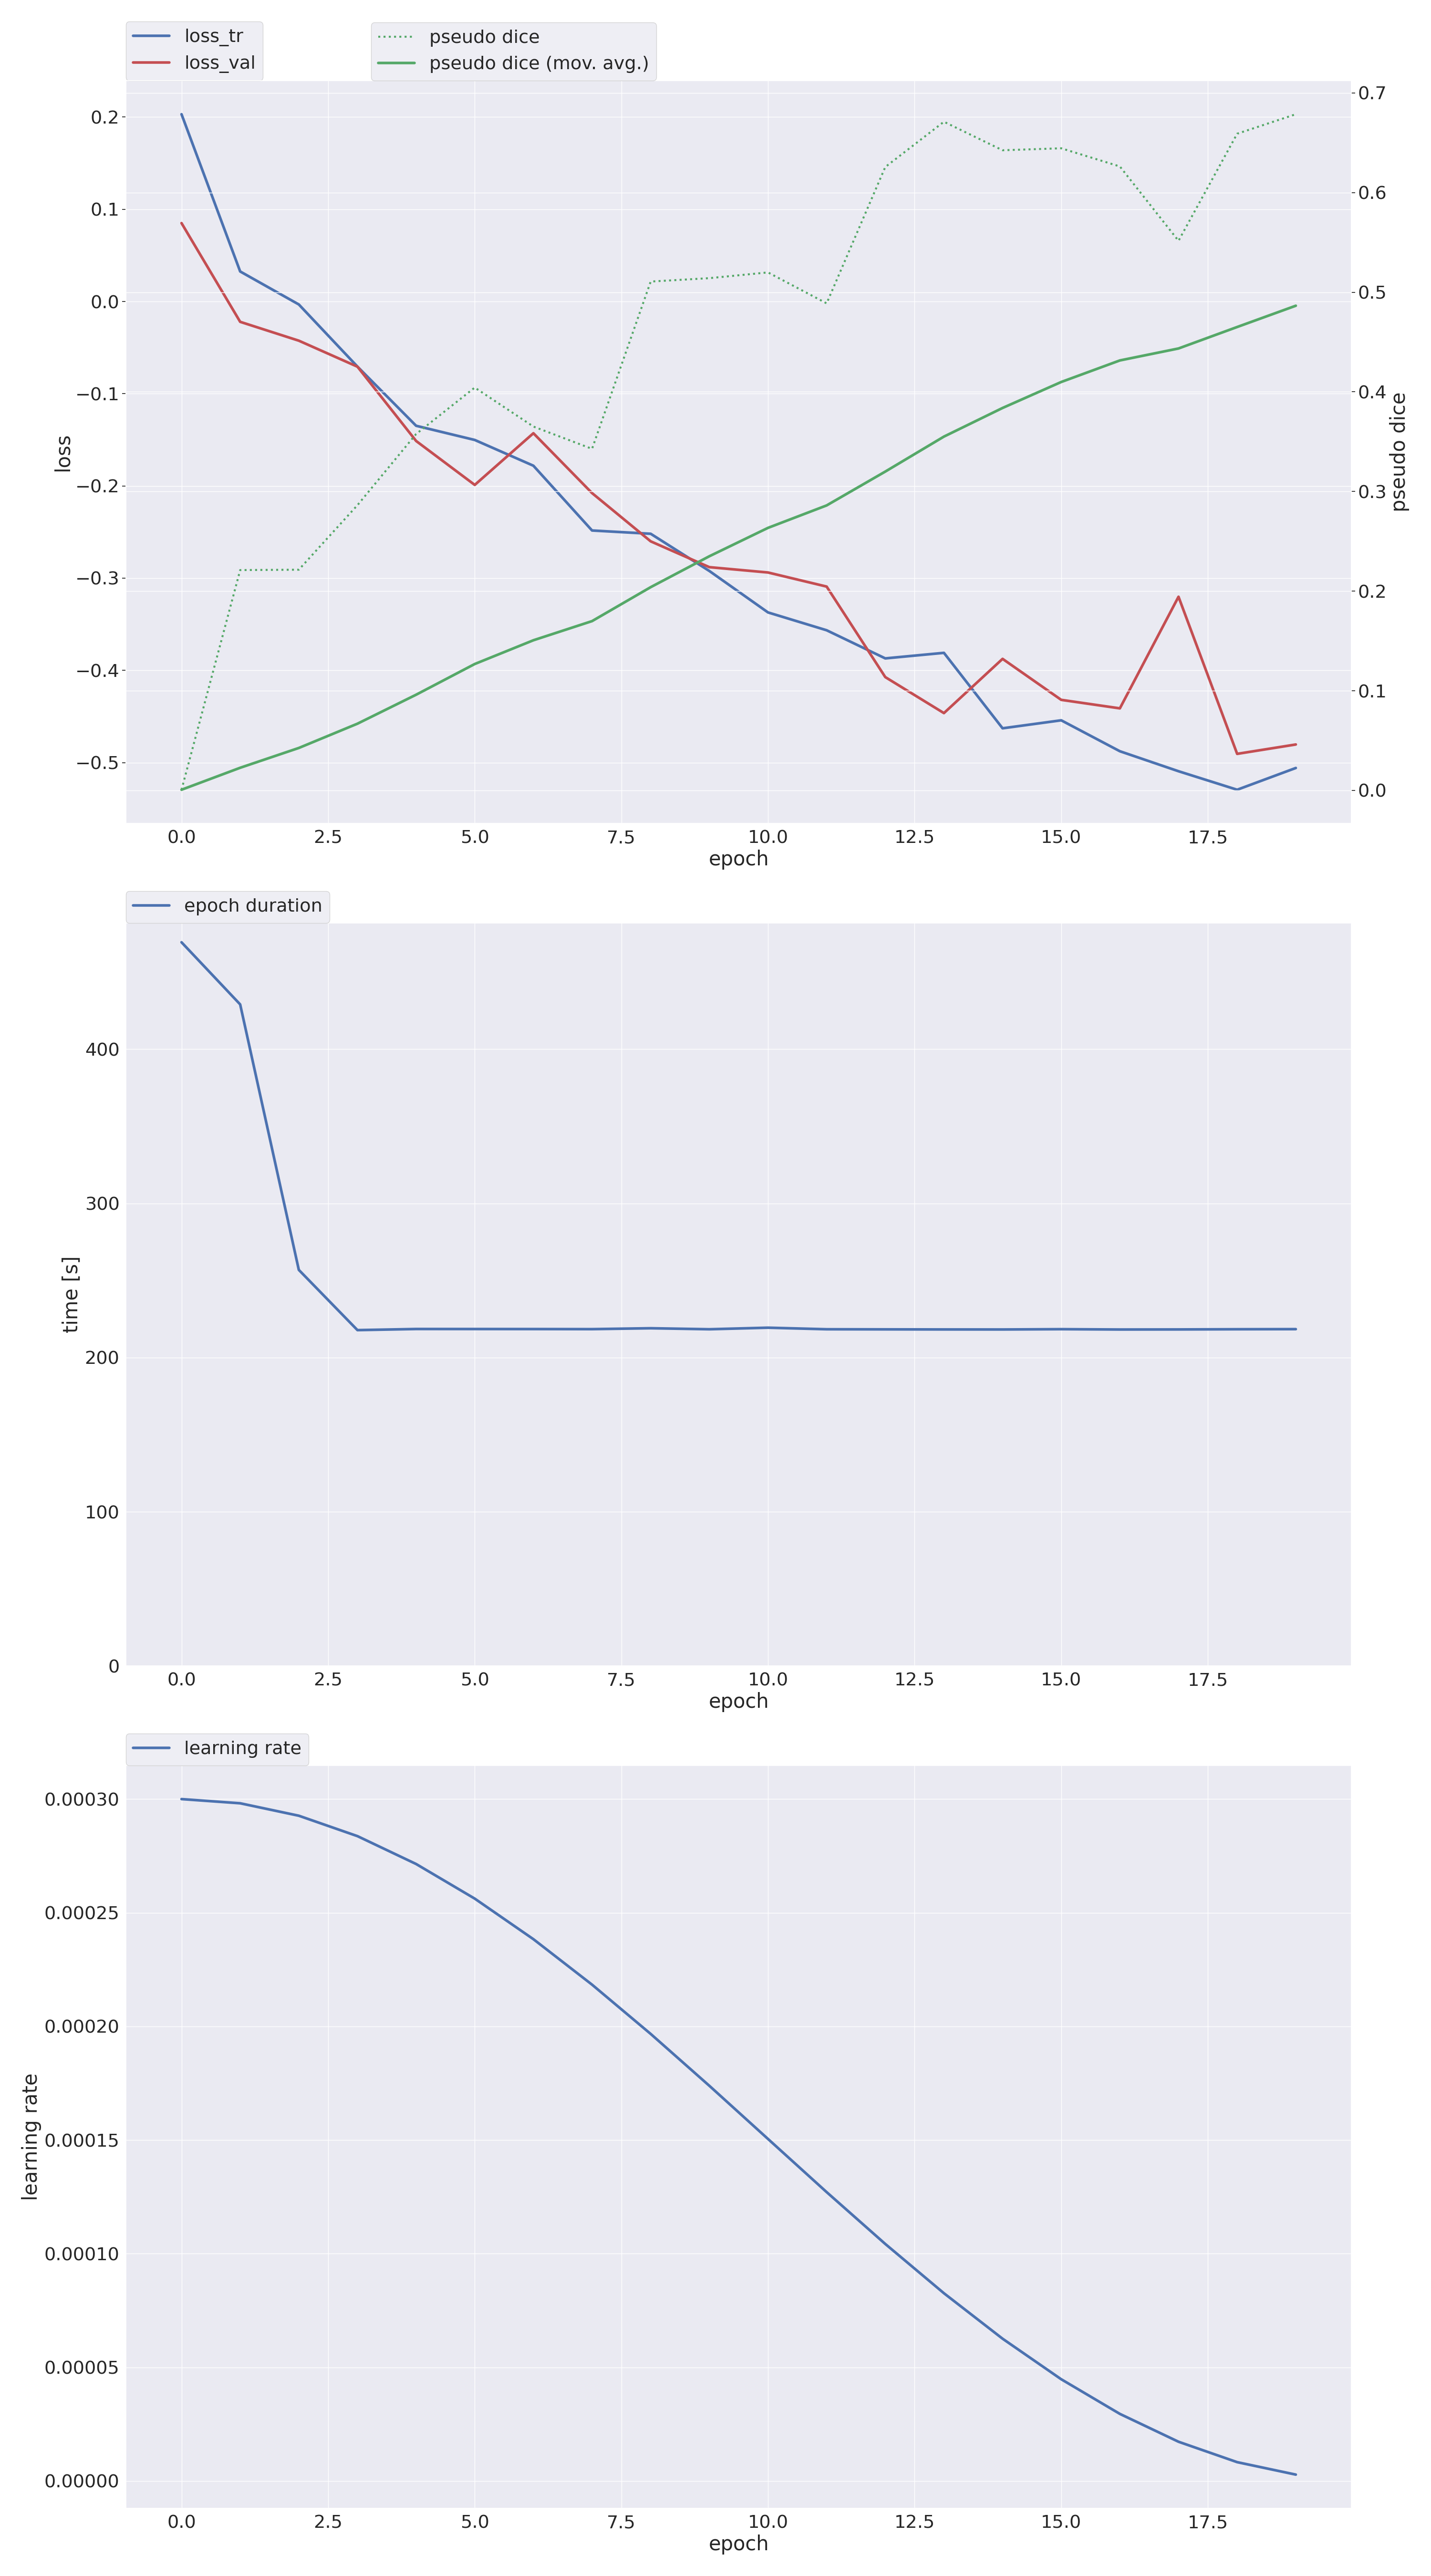

In [13]:
# Kết quả validation & đường cong huấn luyện
from IPython.display import Image as IPImage, display
summ = f"{FOLD_DIR}/validation/summary.json"
CLASS_NAMES = {v: k for k, v in json.load(open(f"{RAW_DS}/dataset.json"))["labels"].items()}
if os.path.isfile(summ):
    s = json.load(open(summ))
    print("Validation mean Dice (foreground):", round(s["foreground_mean"]["Dice"], 4))
    for k, v in s["mean"].items():
        print(f"  class {k} ({CLASS_NAMES.get(int(k), '?')}): Dice={v['Dice']:.4f}  IoU={v['IoU']:.4f}")
else:
    print("Chưa có validation/summary.json (train chưa xong?)")
if os.path.isfile(f"{FOLD_DIR}/progress.png"):
    display(IPImage(f"{FOLD_DIR}/progress.png"))

## 10. Inference trên tập test 

In [14]:
os.chdir(REPO)
CKPT = next(c for c in ["checkpoint_final.pth", "checkpoint_best.pth", "checkpoint_latest.pth"]
            if os.path.isfile(f"{FOLD_DIR}/{c}"))
PRED_DIR = f"{OUT_DIR}/pred_results_fold{FOLD}"
print("checkpoint:", CKPT)
!CUDA_VISIBLE_DEVICES=0 nnUNetv2_predict -i "{RAW_DS}/imagesTs" -o "{PRED_DIR}" -d {DATASET_ID} -c 2d -tr {TRAINER} -f {FOLD} -chk {CKPT} --disable_tta

checkpoint: checkpoint_final.pth

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################

/content/Swin-UMamba/swin_umamba/nnunetv2/inference/predict_from_raw_data.py:87: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(join(model_training_output_dir, f'fold_{f}', checkpoint_name),
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} 

## 11. Đánh giá DSC & NSD (script đánh giá gốc cho ảnh PNG 2D)

In [15]:
os.chdir(REPO)
!python evaluation/endoscopy_DSC_Eval.py --gt_path "{RAW_DS}/labelsTs" --seg_path "{PRED_DIR}" --save_path "{OUT_DIR}/metric_DSC_fold{FOLD}.csv"
!python evaluation/endoscopy_NSD_Eval.py --gt_path "{RAW_DS}/labelsTs" --seg_path "{PRED_DIR}" --save_path "{OUT_DIR}/metric_NSD_fold{FOLD}.csv"

100% 93/93 [00:00<00:00, 122.85it/s]
>>>>>>>>>>>>>>>>>>>>
Average DSC for pred_results_fold0: 0.4245161290322581
<<<<<<<<<<<<<<<<<<<<
100% 93/93 [00:03<00:00, 30.65it/s]
>>>>>>>>>>>>>>>>>>>>
Average NSD for pred_results_fold0: 0.48079139784946234
<<<<<<<<<<<<<<<<<<<<


### 11b. Dice theo từng lớp & độ chính xác phân loại lành/ác
Lớp dự đoán của mỗi ảnh là lớp (lành/ác) chiếm nhiều pixel nhất trong mask dự đoán. Nếu mask không có pixel u nào thì ghi là `none`.

In [3]:
import numpy as np, cv2, pandas as pd
fg = [c for c in sorted(CLASS_NAMES) if c > 0]

def dice(a, b):
    s = a.sum() + b.sum()
    return np.nan if s == 0 else 2.0 * (a & b).sum() / s

rows = []
for n in sorted(f for f in os.listdir(PRED_DIR) if f.endswith(".png")):
    gt = cv2.imread(f"{RAW_DS}/labelsTs/{n}", cv2.IMREAD_UNCHANGED)
    pr = cv2.imread(f"{PRED_DIR}/{n}", cv2.IMREAD_UNCHANGED)
    r = {"case": n[:-4], "Dice_tumor": dice(gt > 0, pr > 0)}
    for c in fg:
        r[f"Dice_{CLASS_NAMES[c]}"] = dice(gt == c, pr == c)
    area = {c: int((pr == c).sum()) for c in fg}
    gt_area = {c: int((gt == c).sum()) for c in fg}
    r["gt_class"] = CLASS_NAMES[max(gt_area, key=gt_area.get)]
    r["pred_class"] = CLASS_NAMES[max(area, key=area.get)] if sum(area.values()) else "none"
    rows.append(r)
df = pd.DataFrame(rows)
df.to_csv(f"{OUT_DIR}/metric_class_fold{FOLD}.csv", index=False)
pd.set_option("display.width", 200)
print(df.round(4).to_string(index=False))
print("\nMean Dice (bỏ qua ảnh không có lớp đó ở cả GT và dự đoán):")
print(df.filter(like="Dice_").mean().round(4).to_string())
if len(fg) > 1:
    acc = (df.gt_class == df.pred_class).mean()
    print(f"\nĐộ chính xác phân loại lành/ác (theo ảnh): {acc:.4f}  ({(df.gt_class == df.pred_class).sum()}/{len(df)})")
    print(pd.crosstab(df.gt_class, df.pred_class, rownames=["GT"], colnames=["Pred"]))

     case  Dice_tumor  Dice_benign  Dice_malignant  gt_class pred_class
IMG000001      0.4929       0.0000          0.5521 malignant  malignant
IMG000002      0.7334          NaN          0.7334 malignant  malignant
IMG000008      0.7980          NaN          0.7980 malignant  malignant
IMG000032      0.8943       0.0000          0.0000 malignant     benign
IMG000034      0.8965       0.0000          0.0000 malignant     benign
IMG000058      0.9308       0.0000          0.9285 malignant  malignant
IMG000070      0.7883          NaN          0.7883 malignant  malignant
IMG000198      0.6228       0.0000          0.6229 malignant  malignant
IMG000232      0.9228       0.0000          0.0000 malignant     benign
IMG000301      0.0000       0.0000             NaN    benign       none
IMG000331      0.0000       0.0000             NaN    benign       none
IMG000344      0.5461       0.5461             NaN    benign     benign
IMG000366      0.0000       0.0000             NaN    benign    

## 12. Trực quan hoá vài kết quả

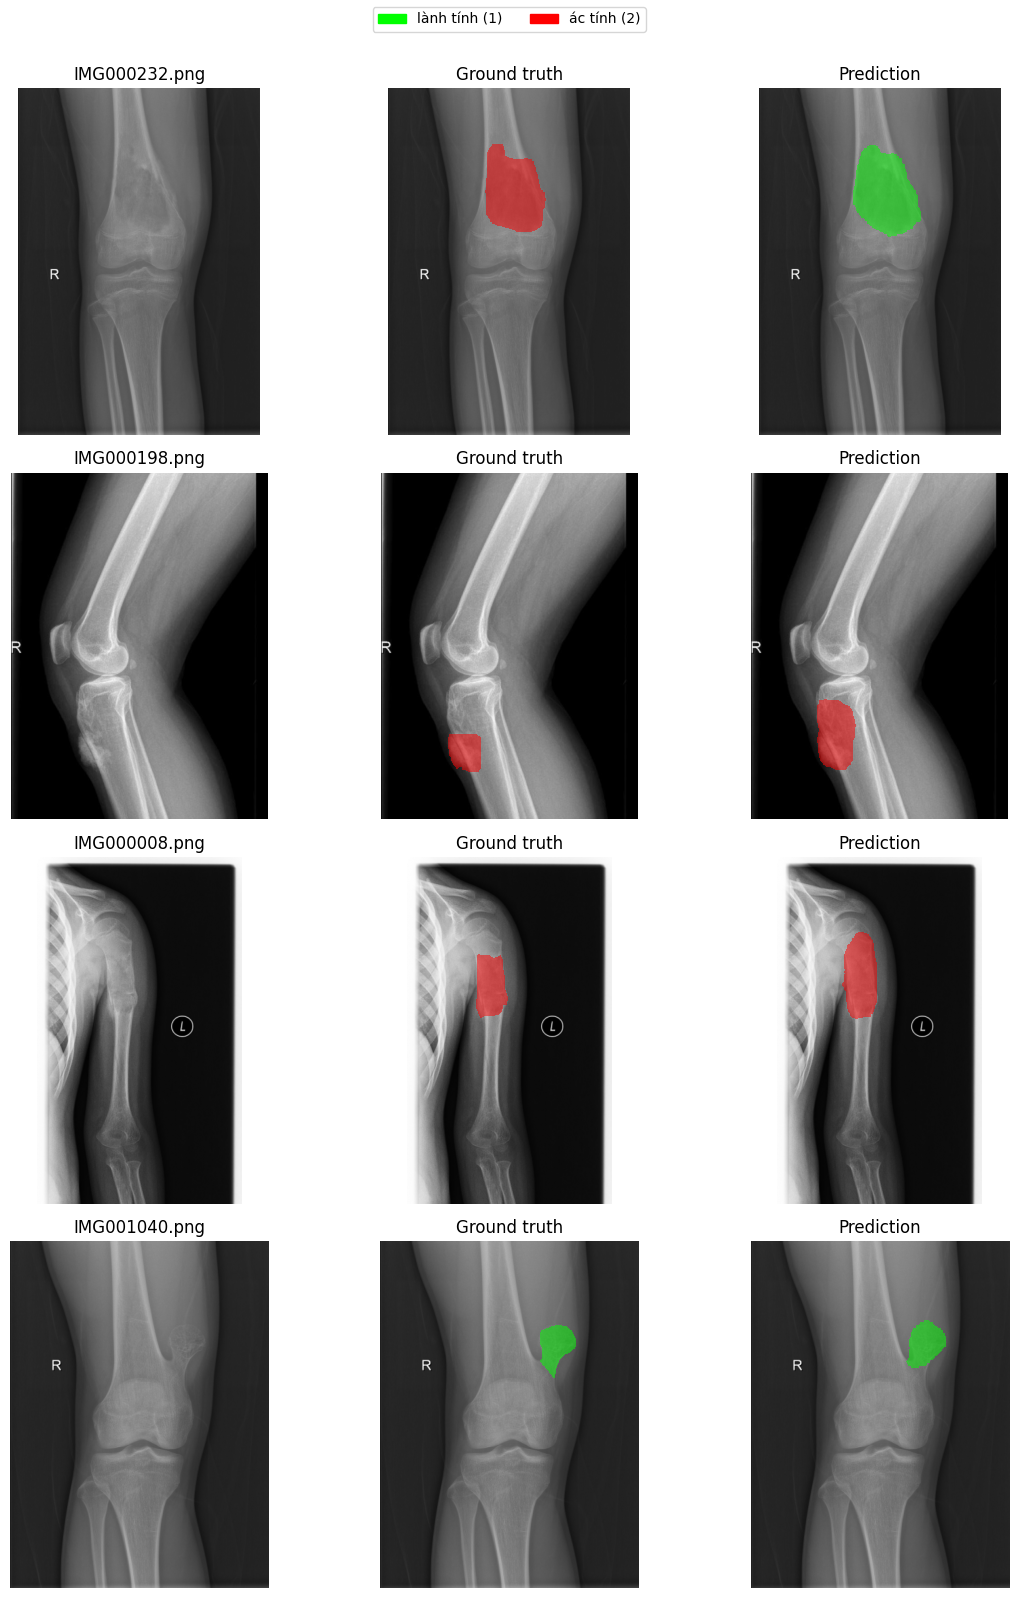

In [4]:
import random
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
%matplotlib inline
CMAP = ListedColormap(["black", "lime", "red"])   # 1 = lành tính (xanh), 2 = ác tính (đỏ)

names = sorted(n for n in os.listdir(PRED_DIR) if n.endswith(".png"))
random.Random(0).shuffle(names)
k = min(4, len(names))
fig, ax = plt.subplots(k, 3, figsize=(12, 4 * k), squeeze=False)
for i, n in enumerate(names[:k]):
    img = cv2.imread(f"{RAW_DS}/imagesTs/{n[:-4]}_0000.png", cv2.IMREAD_GRAYSCALE)
    gt  = cv2.imread(f"{RAW_DS}/labelsTs/{n}", cv2.IMREAD_UNCHANGED)
    pr  = cv2.imread(f"{PRED_DIR}/{n}", cv2.IMREAD_UNCHANGED)
    ax[i, 0].imshow(img, cmap="gray"); ax[i, 0].set_title(n)
    ax[i, 1].imshow(img, cmap="gray"); ax[i, 1].imshow(np.ma.masked_equal(gt, 0), alpha=0.5, cmap=CMAP, vmin=0, vmax=2, interpolation="nearest"); ax[i, 1].set_title("Ground truth")
    ax[i, 2].imshow(img, cmap="gray"); ax[i, 2].imshow(np.ma.masked_equal(pr, 0), alpha=0.5, cmap=CMAP, vmin=0, vmax=2, interpolation="nearest"); ax[i, 2].set_title("Prediction")
    for a in ax[i]: a.axis("off")
fig.legend(handles=[Patch(color="lime", label="lành tính (1)"), Patch(color="red", label="ác tính (2)")], loc="upper center", ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## 13. Kết quả đã lưu
Toàn bộ checkpoint, log, `progress.png`, kết quả validation, dự đoán trên tập test và các file CSV metric nằm trong `RESULTS_DIR` trên Google Drive (`MyDrive/Swin-UMamba-BTXRD/results/ep<EPOCHS>/`).

In [5]:
!du -sh "{RESULTS_DIR}"
!ls -la "{FOLD_DIR}"

1.4G	/content/drive/MyDrive/Swin-UMamba-BTXRD/results/ep20
total 1404681
drwx------ 3 root root      4096 Nov 22 10:56 .
drwx------ 4 root root      4096 Nov 22 11:45 ..
-rw------- 1 root root 718910841 Nov 22 10:54 checkpoint_best.pth
-rw------- 1 root root 718911869 Nov 22 10:54 checkpoint_final.pth
-rw------- 1 root root     11416 Nov 22 09:46 debug.json
-rw------- 1 root root    515474 Nov 22 10:54 progress.png
-rw------- 1 root root      4535 Nov 22 09:16 training_log_2026_11_22_09_00_51.txt
-rw------- 1 root root     26045 Nov 22 10:56 training_log_2026_11_22_09_45_56.txt
drwx------ 2 root root      4096 Nov 22 10:56 validation
